# DG-ALETSK: a handful of genes and rules out of 2000 features

This notebook follows, one step at a time, the classifier of

> G. Xue, J. Wang, B. Yuan and C. Dai, "DG-ALETSK: a high-dimensional fuzzy approach with
> simultaneous feature selection and rule extraction", *IEEE Transactions on Fuzzy
> Systems*, vol. 31, no. 11, 2023.

on Colon, one of the datasets of the article. DG-ALETSK builds a rule base with one rule
per training sample, computes the firing strengths with an adaptive softmin, and trains
two groups of gates that switch features and rules off. The notebook is a short version
of the script `examples/reproductions/dgaletsk_2023.py`, which repeats the ten folds five
times; here one repetition runs in a few minutes.

1. settings and reproducibility;
2. the data;
3. DG-ALETSK on one fold;
4. what the fitted model looks like;
5. ten folds, next to the article.

## 1. Settings and reproducibility

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import fetch_openml
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler

import highfis
from highfis import DGALETSKClassifier

In [2]:
SEED = 0
FOLDS = 10
THREADS = 4

# Table V of the article, Colon: accuracy in percent, selected features, extracted rules.
ARTICLE = (81.95, 6.80, 6.42)

torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)
highfis.set_mf_cache_enabled(False)

## 2. The data

Colon is a gene-expression dataset: 62 tissue samples, 2000 genes, two classes. OpenML
stores it as a sparse matrix.

In [3]:
bunch = fetch_openml(data_id=1432, as_frame=False, parser="liac-arff")
data = bunch.data.toarray() if hasattr(bunch.data, "toarray") else bunch.data
features = np.asarray(data, dtype=np.float32)
labels = np.unique(bunch.target, return_inverse=True)[1]

print(f"{features.shape[0]} samples, {features.shape[1]} features")
print(f"samples per class: {np.bincount(labels).tolist()}")

62 samples, 2000 features
samples per class: [40, 22]


The first of ten folds is followed in detail. The article scales the inputs to [0, 1],
with the range of the training part. A test part has six or seven samples: one sample is
about 15 points of the accuracy of a fold.

In [4]:
folds = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
train, test = next(folds.split(features, labels))

scaler = MinMaxScaler().fit(features[train])
x_train, x_test = scaler.transform(features[train]), scaler.transform(features[test])
y_train, y_test = labels[train], labels[test]

print(f"training: {len(x_train)} samples, test: {len(x_test)} samples")

training: 55 samples, test: 7 samples


## 3. DG-ALETSK on one fold

The rule base has one rule per training sample, 55 rules of 2000 conditions. A gate on
each feature and on each rule is trained for 10 epochs, with batches of 10% of the
training samples. The features and rules whose gates stay below a threshold are removed;
the threshold is chosen among candidate values on a part of the training data. The
remaining system is then fine-tuned.

These are the defaults of `DGALETSKClassifier`.

In [5]:
model = DGALETSKClassifier(random_state=SEED).fit(x_train, y_train)

print(f"selected features: {len(model.selected_features_)} of {x_train.shape[1]}")
print(f"extracted rules: {model.model_.n_rules} of {x_train.shape[0]}")
print(f"training accuracy: {100 * model.score(x_train, y_train):.1f}%")
print(f"test accuracy: {100 * model.score(x_test, y_test):.1f}%")
print(f"selected genes (columns of the data): {sorted(int(d) for d in model.selected_features_)}")

selected features: 7 of 2000
extracted rules: 2 of 55
training accuracy: 90.9%
test accuracy: 85.7%
selected genes (columns of the data): [248, 364, 376, 492, 821, 1422, 1770]


The training loss of the two phases, one after the other:

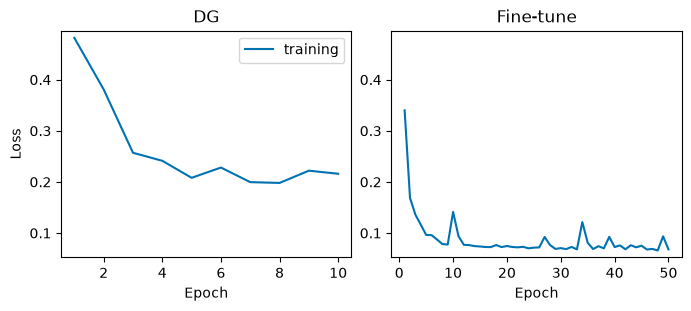

In [6]:
model.plot_history()

The gates of the selected genes and of the extracted rules at the end of the gate phase,
with the thresholds that the search chose. In the plots and in the sentences below the
genes are numbered from one, so `x249` is column 248 of the data:

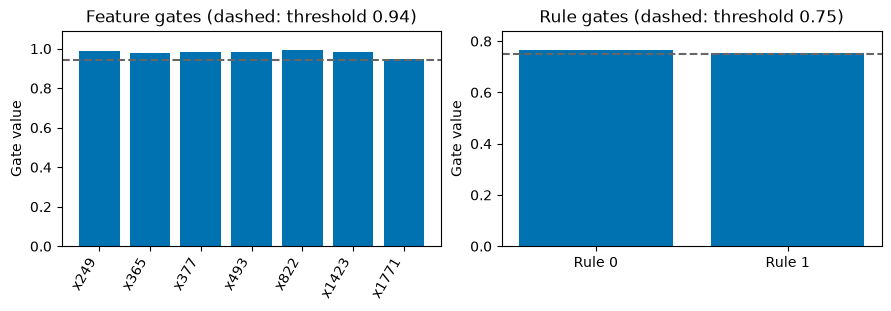

In [7]:
model.plot_gates()

## 4. What the fitted model looks like

The model that predicts is small enough to be read. The rules as sentences; there the
genes are numbered from one, so `x249` is column 248 of the data:

In [8]:
model.rules_as_text(top_features=4)

Rule 0: IF x365 is high AND x1423 is high AND x1771 is high
           AND the other 4 features are low
        THEN 0: 1.26 - 0.20 * x377 - 0.04 * x822 + 0.04 * x1771
                - 0.03 * x1423 + ...
             1: -0.04 - 0.16 * x1771 - 0.14 * x493 - 0.13 * x365
                - 0.11 * x1423 + ...
Rule 1: IF x365 is low AND x1423 is low AND x1771 is low
           AND the other 4 features are high
        THEN 0: 1.12 - 0.55 * x377 - 0.37 * x249 - 0.31 * x493
                - 0.29 * x822 + ...
             1: 0.14 + 0.48 * x377 + 0.43 * x249 + 0.27 * x822
                - 0.25 * x1771 + ...

The fuzzy sets of the selected genes:

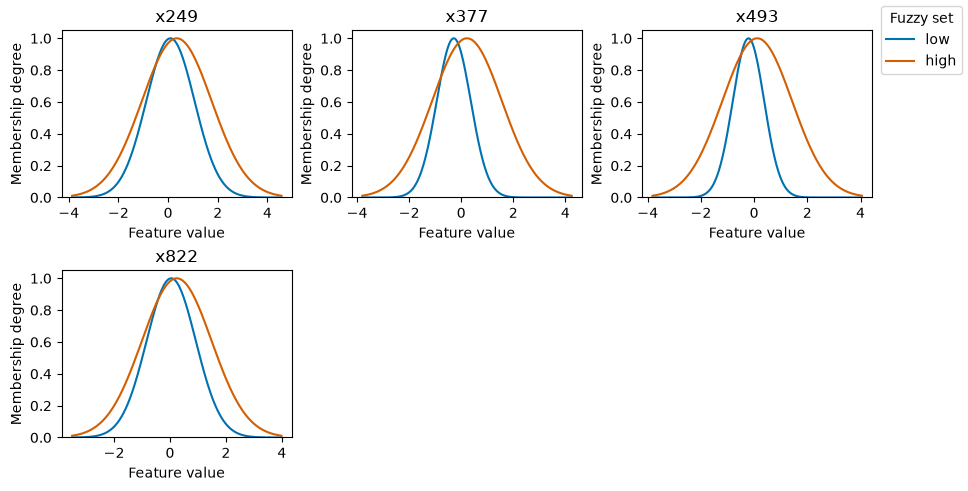

In [9]:
model.plot_memberships(max_features=4)

The confusion matrix and the margins, on the training part and on the seven test samples:

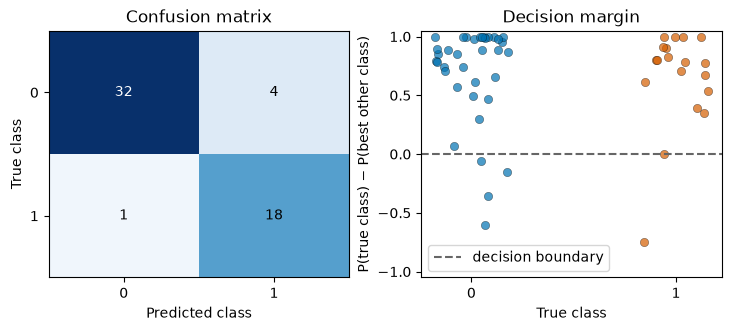

<Figure size 640x480 with 0 Axes>

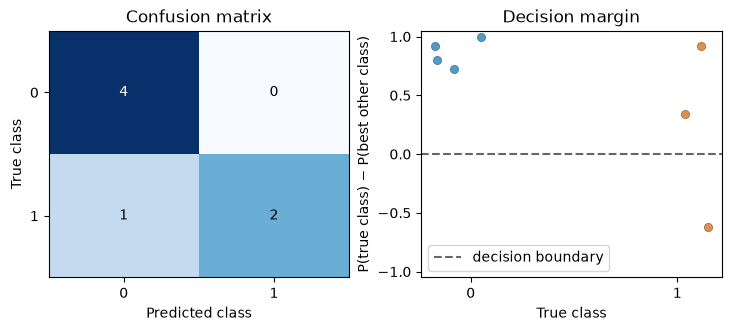

<Figure size 640x480 with 0 Axes>

In [10]:
model.plot_diagnostics(x_train, y_train)
plt.suptitle("training part", y=1.02)
plt.show()

model.plot_diagnostics(x_test, y_test)
plt.suptitle("test part", y=1.02)
plt.show()

The two classes in the plane of the two selected genes with the largest gates, on the
training part:

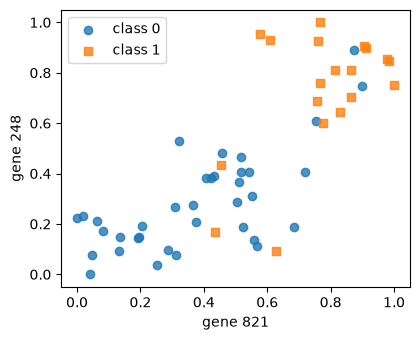

In [11]:
order = np.argsort(model.get_feature_gates())[::-1][:2]
first, second = (int(model.selected_features_[position]) for position in order)

fig, ax = plt.subplots(figsize=(4.5, 3.6))
for value, marker in zip(np.unique(y_train), ("o", "s")):
    mask = y_train == value
    ax.scatter(x_train[mask, first], x_train[mask, second], marker=marker, label=f"class {value}", alpha=0.8)
ax.set_xlabel(f"gene {first}")
ax.set_ylabel(f"gene {second}")
ax.legend()
plt.show()

A summary of the model and of its training, in one call:

In [12]:
model.summary()

DGALETSKClassifier
  task               classification, 2 classes
  features           2000 seen in fit, 7 used by the model
  rules              2 (rule base: pfrb)
  fuzzy sets         2 per feature, GaussianMF
  firing strength    DGALETSKRuleLayer
  defuzzifier        SoftmaxLogDefuzzifier
  consequents        GatedClassificationConsequentLayer
  parameters         83 trainable (28 antecedent, 48 consequent)
Training (batch size 6)
  phase        epochs  rate  loss first -> last  accuracy
  gates            10  0.01    0.4817 -> 0.2159    0.6545
  fine-tuning      50  0.01    0.3400 -> 0.0680    0.9091

How the rules produce the prediction of the first test sample. The output is the sum of
what each rule contributes, and the predicted class is the one with the largest value:

In [13]:
model.explain(x_test[0])

Prediction: 1
Output, the sum of the contributions of the 2 rules: 0: +0.04, 1: +0.96
Rule 1, weight 0.89: contributes 0: -0.07, 1: +0.99
    IF x365 is low AND x1423 is low AND x1771 is low
       AND the other 4 features are high
Rule 0, weight 0.11: contributes 0: +0.11, 1: -0.03
    IF x365 is high AND x1423 is high AND x1771 is high
       AND the other 4 features are low

How well the rules cover the samples: for each sample, the mean membership degree in its
best-matching rule. A test sample with a coverage well below the training samples would
lie outside the region the rules were built on:

In [14]:
inside, outside = model.coverage(x_train), model.coverage(x_test)
print(f"training part: min {inside.min():.2f}, median {np.median(inside):.2f}")
print(f"test part:     min {outside.min():.2f}, median {np.median(outside):.2f}")

training part: min 0.84, median 0.96
test part:     min 0.91, median 0.97


## 5. Ten folds, next to the article

In [15]:
runs, selections = [], []

for train, test in StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED).split(features, labels):
    scaler = MinMaxScaler().fit(features[train])
    a_train, a_test = scaler.transform(features[train]), scaler.transform(features[test])

    fitted = DGALETSKClassifier(random_state=SEED).fit(a_train, labels[train])
    runs.append((100 * fitted.score(a_test, labels[test]), len(fitted.selected_features_), fitted.model_.n_rules))
    selections.append(fitted.selected_features_)

runs = np.asarray(runs)
print(f"{'':10s} {'accuracy':>9s} {'features':>9s} {'rules':>6s}")
print(f"{'article':10s} {ARTICLE[0]:9.2f} {ARTICLE[1]:9.2f} {ARTICLE[2]:6.2f}")
print(f"{'highFIS':10s} {runs[:, 0].mean():9.2f} {runs[:, 1].mean():9.2f} {runs[:, 2].mean():6.2f}")

            accuracy  features  rules
article        81.95      6.80   6.42
highFIS        87.62      8.50   5.10


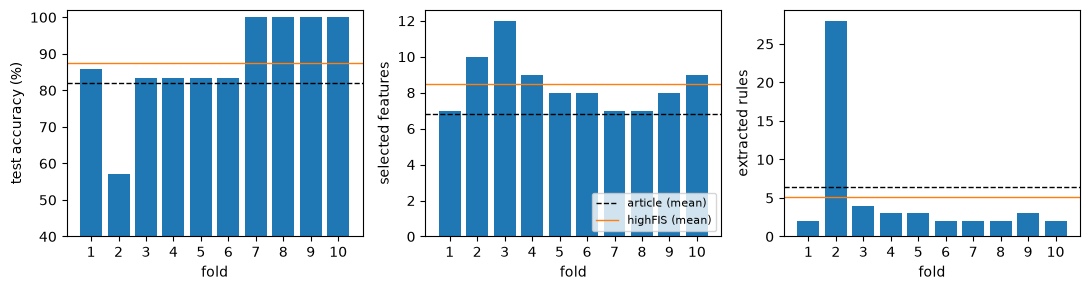

In [16]:
LOWER = 40

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
folds_axis = np.arange(1, FOLDS + 1)
for ax, column, label, reported in zip(axes, range(3), ["test accuracy (%)", "selected features", "extracted rules"], ARTICLE):
    ax.bar(folds_axis, runs[:, column])
    ax.axhline(reported, color="black", linestyle="--", linewidth=1, label="article (mean)")
    ax.axhline(runs[:, column].mean(), color="tab:orange", linewidth=1, label="highFIS (mean)")
    ax.set_xticks(folds_axis)
    ax.set_xlabel("fold")
    ax.set_ylabel(label)
axes[0].set_ylim(LOWER, 102)
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

The genes that are selected in more than one fold. With 2000 genes and 55 training
samples, many small sets of genes separate the classes, so the folds agree on a few genes
only:

In [17]:
genes, counts = np.unique(np.concatenate(selections), return_counts=True)
repeated = [(int(gene), int(count)) for gene, count in zip(genes, counts) if count > 1]

print(f"distinct genes selected over the {FOLDS} folds: {len(genes)}")
print("gene: folds that select it")
for gene, count in sorted(repeated, key=lambda pair: -pair[1]):
    print(f"{gene:5d}: {count}")

distinct genes selected over the 10 folds: 25
gene: folds that select it
  376: 10
  492: 10
  821: 9
  248: 8
  624: 7
 1422: 7
   25: 4
 1770: 4
  364: 3
 1621: 3
 1255: 2
 1345: 2
 1493: 2
 1503: 2
 1634: 2


The script repeats the ten folds five times, as the article does; over the 50 runs it
gives 86.95% with 7.18 genes and 6.98 rules.